# 🕸️ LangGraph 기초부터 차근차근
---
## 🧭 학습 로드맵

| 단계 | # | 주제 | 핵심 키워드 | LLM 필요? |
|:----:|:-:|------|-------------|:---------:|
| 🌱 **기초** | 1 | LangGraph 란? | State · Node · Edge · 슈퍼스텝 | ❌ |
| | 2 | 첫 번째 그래프 | `StateGraph`, `compile`, `invoke` | ❌ |
| | 3 | 노드 여러 개 연결 | 순차 실행, 상태 갱신 규칙 | ❌ |
| | 4 | State 스키마 | `TypedDict` / `dataclass` / `Pydantic`, 입력·출력 스키마 | ❌ |
| | 5 | 리듀서 | `Annotated`, `operator.add`, `add_messages` | ❌ |
| 🌿 **흐름 제어** | 6 | 조건부 엣지 | `add_conditional_edges` | ❌ |
| | 7 | 반복(사이클) | 루프, `recursion_limit` | ❌ |
| | 8 | 병렬 실행 | fan-out / fan-in | ❌ |
| | 9 | `Send` | 개수가 정해지지 않은 병렬(Map-Reduce) | ❌ |
| | 10 | `Command` | 상태 업데이트 + 이동 한 번에 | ❌ |
| | 11 | 런타임 컨텍스트 | `context_schema`, `Runtime` | ❌ |
| 🌳 **LLM 에이전트** | 12 | LLM 노드 · 챗봇 | `MessagesState` | ✅ |
| | 13 | LLM 라우팅 | 구조화된 출력 + 조건부 엣지 | ✅ |
| | 14 | 도구 에이전트 (ReAct) | `ToolNode`, `tools_condition` | ✅ |
| 🌲 **운영 기능** | 15 | 메모리 | 체크포인터, `thread_id` | ✅ |
| | 16 | 스트리밍 | `stream_mode` 5가지 | ✅ |
| | 17 | Human-in-the-loop | `interrupt`, `Command(resume)` | ❌ |
| | 18 | 에러 처리 | `RetryPolicy` | ❌ |
| | 19 | 서브그래프 | 그래프 안의 그래프 | ❌ |
| 🏁 **종합** | 20 | 글쓰기 에이전트 | 루프 + 사람 피드백 + LLM | ✅ |
| | 21 | 정리 | 치트시트 · 연습문제 · 다음 단계 | ❌ |

> **한눈에 보기**
> - LangGraph = 상태(State)를 가진 작업 흐름을 노드 + 엣지 그래프로 설계·실행. State = 공유 화이트보드, Node = 바뀐 칸만 적는 직원, Edge = 다음 순서
> - 4단계: State 정의 → Node 함수 → `StateGraph`에 `add_node`/`add_edge`(또는 `add_sequence`) → `compile()` 후 `invoke`/`batch`/`stream`
> - 노드는 **바뀐 필드만 dict로 반환**, 반환 안 한 필드는 유지, 반환한 필드는 덮어쓰기. 실행 단위는 슈퍼스텝
> - State 스키마: TypedDict / dataclass(기본값) / Pydantic(검증), `input_schema`·`output_schema`로 밖에 보일 필드 선택
> - 정리 문서: [LangGraph기본.md](LangGraph기본.md) · 노트북 로드맵 1~4장, 강의 슬라이드 이미지 포함, 📝 정리 셀은 직접 정리

## 0️⃣ 환경 설정

In [1]:
import sys
from importlib.metadata import version

print("Python           :", sys.version.split()[0])
for pkg in ("langgraph", "langchain", "langchain-core", "langchain-openai"):
    print(f"{pkg:17s}:", version(pkg))

MODEL = "gpt-4o-mini"      # 12장부터 사용할 모델

Python           : 3.12.10
langgraph        : 1.2.16
langchain        : 1.4.6
langchain-core   : 1.6.12
langchain-openai : 1.7.2


# 🌱 1장. LangGraph 란 무엇인가?

## 📖 한 줄 정의

> **LangGraph = "상태(State)를 가진 작업 흐름"을 *그래프*(노드 + 엣지)로 설계하고 실행해 주는 라이브러리**

LangChain 이 *"LLM 을 부품(모델·프롬프트·도구)으로 쓰기 쉽게 만든 도구상자"* 라면,
LangGraph 는 *"그 부품들을 **어떤 순서와 조건으로** 움직일지 정하는 **설계도 + 실행 엔진**"* 입니다.

---
- LCEL: 순차·병렬·조건부 처리를 포함하는 데이터 처리 파이프라인에 적합
   - RunnableSequence, RunnableParallel, RunnableBranch
- LangGraph: 상태를 공유하면서 복잡하게 분기·반복하고, 중단·재개까지 관리하는 워크플로에 적합

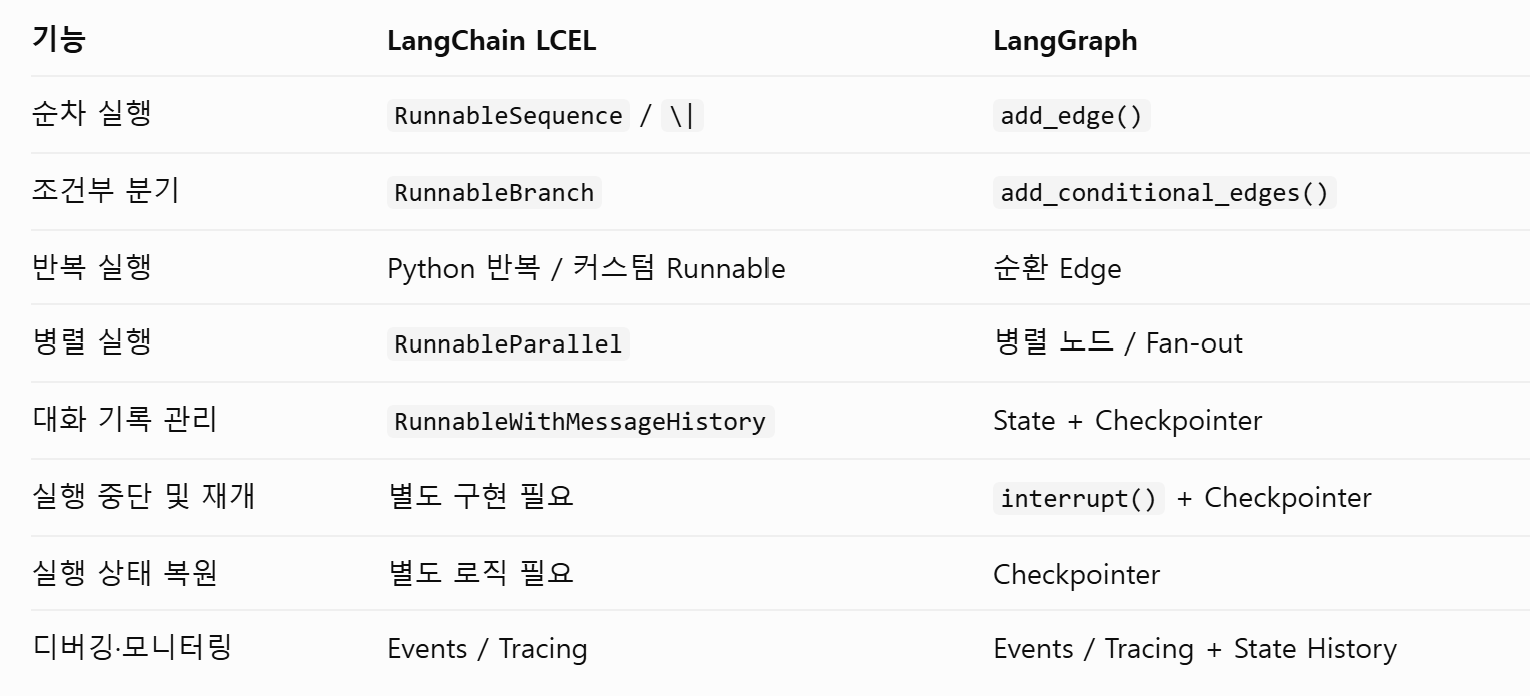



## 🧠 핵심 비유: "공유 화이트보드가 있는 사무실"

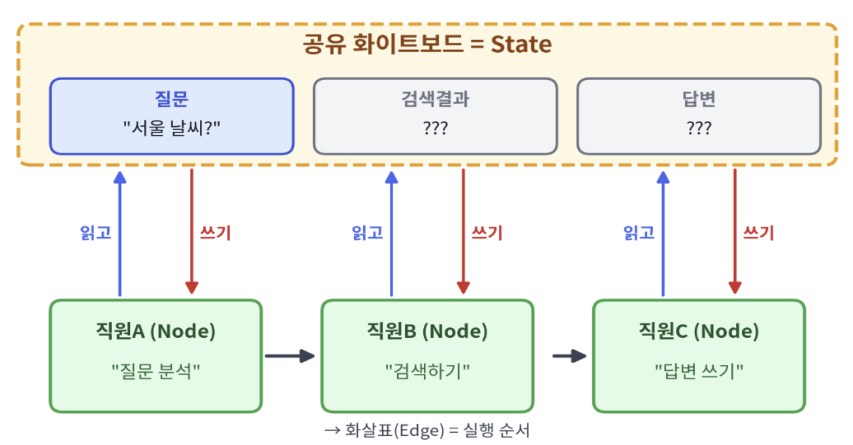

- **State(상태)** = 모든 직원이 함께 보는 **화이트보드** (그래프 전체가 공유하는 데이터)
- **Node(노드)** = 화이트보드를 *읽고*, 자기 일을 하고, **바뀐 부분만 적는** 직원 (파이썬 함수, 서브에이전트)
- **Edge(엣지)** = **"다음에 누가 일할지"** 를 정하는 화살표 (고정 화살표 / 조건부 화살표)

---

## 🧱 3대 구성요소

| 구성요소 | 정체 | 코드에서는 | 핵심 규칙 |
|----------|------|------------|-----------|
| **State** | 그래프가 공유하는 데이터 | `TypedDict` (또는 dataclass / Pydantic) | 필드마다 **갱신 규칙(리듀서)** 지정 가능 |
| **Node** | 일을 하는 함수 | `def node(state) -> dict` | state 를 받아 **바뀐 필드만 담은 dict** 반환 |
| **Edge** | 노드 사이의 연결 | `add_edge`, `add_conditional_edges` | `START` 에서 시작, `END` 에서 종료 |

그리고 이 셋을 조립해 `compile()` 하면 **실행 가능한 앱**(`Runnable`)이 됩니다 → `invoke` / `stream` / `batch` 를 그대로 쓸 수 있습니다. (LangChain 을 학습한 create_agent()에 의해 만들어진 CompiledStateGraph와 비슷)

---

## ⚙️ 실행 모델: "슈퍼스텝(super-step)"

LangGraph 는 구글의 그래프 처리 모델 **Pregel** 에서 영감을 받아, 그래프를 **단계(슈퍼스텝)** 단위로 실행합니다.

> Pregel(프레겔)은 구글(Google)이 수십억 개의 노드와 간선으로 이루어진 대규모 그래프 데이터(예: 소셜 네트워크, 웹 링크 구조 등)를 분산 처리하기 위해 개발한 시스템 및 프로그래밍 모델입니다.

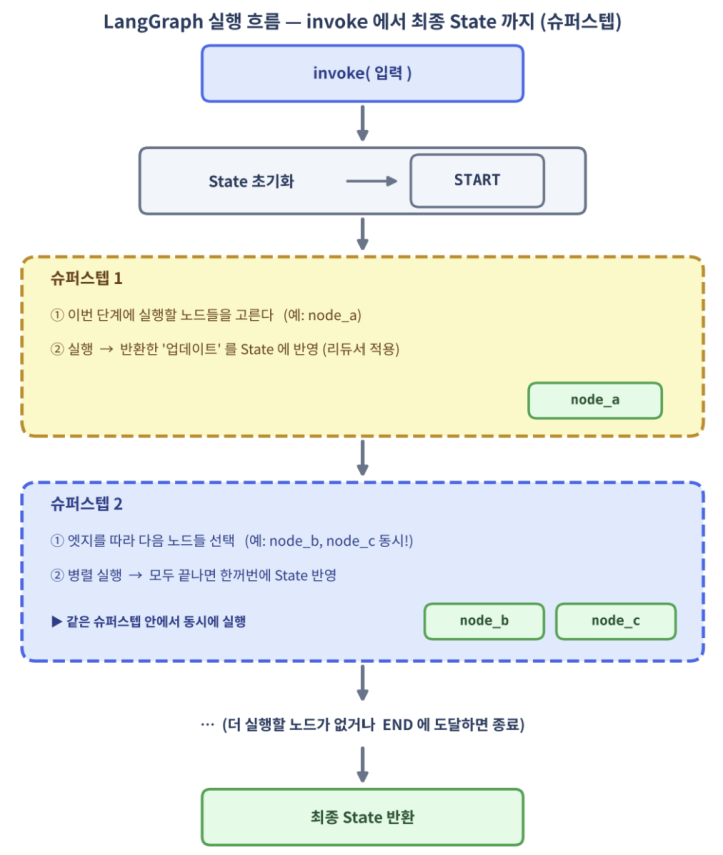

> 📌 기억할 점: 같은 슈퍼스텝(Superstep)에서 실행되는 노드들은 서로의 실행 결과를 즉시 공유하지 않습니다. 모든 노드는 해당 슈퍼스텝이 시작될 때의 State를 기준으로 실행되며, 각 노드의 결과는 슈퍼스텝이 완료된 후 일괄 반영되어 다음 슈퍼스텝부터 사용할 수 있습니다. (8장 병렬 실행에서 중요)

---

## 🎁 LangGraph 가 기본 제공하는 것

| 기능 | 설명 | 다루는 장 |
|------|------|:---------:|
| 🔀 분기 · 🔁 반복 · ⚡ 병렬 | 흐름 제어 | 6 ~ 10 |
| 💾 **체크포인터(영속성)** | 매 단계 State 를 저장 → 메모리 · 재개 · 시간여행 | 15 |
| 📡 **스트리밍** | 단계별 / 토큰별 / 커스텀 이벤트 | 16 |
| 🙋 **Human-in-the-loop** | 실행을 멈추고 사람에게 묻기 | 17 |
| 🔁 재시도 · 🧩 서브그래프 | 안정성 · 모듈화 | 18, 19 |
| 🖼️ 시각화 | 그래프를 그림으로 출력 | 2 |

**LangGraph에서 슈퍼스텝(Superstep)은 하나 이상의 노드가 실행되는 하나의 실행 단계를 의미합니다.***

- 노드(Node): 실제 작업을 수행하는 함수 또는 에이전트
- 슈퍼스텝(Superstep): 실행 가능한 노드들이 함께 실행되는 하나의 단계

**슈퍼스텝(Superstep)은 노드들을 실행하고, 그 결과를 State에 반영한 뒤 다음 실행 단계로 넘어가는 기본 단위입니다.**

---

## 🌱 2장. 첫 번째 그래프 — `START → 노드 → END`

### 📖 이론: 그래프를 만드는 4단계

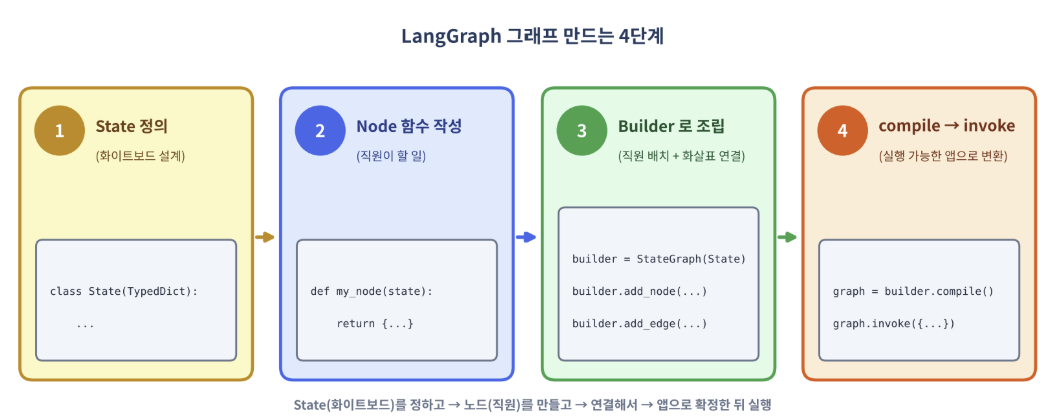

| 용어 | 설명 |
|------|------|
| `StateGraph(State)` | 그래프 **설계도(Builder)** 를 만든다. State 스키마를 알려 줌 |
| `add_node("이름", 함수)` | 노드 등록. 이름은 문자열, 함수는 `state` 를 받는 파이썬 함수 |
| `add_edge(A, B)` | A 가 끝나면 B 를 실행 |
| `START` / `END` | 가상의 **시작 / 끝** 지점 (직접 만드는 노드가 아님) |
| `compile()` | 설계도를 **실행 가능한 그래프**로 변환 (연결 오류도 이때 검사) |
| `invoke(입력)` | 실행하고 **최종 State(dict)** 를 반환 |

#### 📌 노드 함수(Node Function)의 작성 규칙

- **아규먼트로 State를 입력받습니다.** 노드 함수는 현재 그래프의 State를 인자로 받아 필요한 데이터를 읽고 처리합니다.
- **변경할 필드만 딕셔너리(dict)로 반환합니다.** 반환된 값은 State에 반영되며, 반환하지 않은 필드는 기존 값을 유지합니다. 단, Reducer가 설정된 필드는 해당 병합 규칙을 따릅니다.
- **State를 직접 수정하지 않고 반환값으로 업데이트합니다.** state["x"] = ...처럼 입력 State를 직접 변경하기보다는 **return {"x": ...}** 형태로 변경 사항을 명시합니다.

In [2]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

# ① State 정의: 화이트보드에 어떤 칸이 있는지 설계 : State 스키마
class GreetState(TypedDict):
    name: str          # 입력으로 받을 값
    greeting: str      # 노드가 채워 넣을 값

# ② Node 함수: state 를 받아서 "바뀐 부분만" dict 로 반환
def make_greeting(state: GreetState) -> dict:
    print(f"   ▶ make_greeting 실행! 받은 state = {state}")
    return {"greeting": f"안녕하세요, {state['name']}님! 👋"}

# ③ Builder 로 조립: 노드 등록 + 화살표 연결
builder = StateGraph(GreetState)
builder.add_node("make_greeting", make_greeting)
builder.add_edge(START, "make_greeting")      # 시작 → make_greeting
builder.add_edge("make_greeting", END)        # make_greeting → 끝

# ④ 컴파일 → 실행
graph = builder.compile()
result = graph.invoke({"name": "유니코"})       # greeting 은 아직 없어도 OK (노드가 채워 줌)

print("\n✅ 최종 결과:", result)
print("타입:", type(graph).__name__)

   ▶ make_greeting 실행! 받은 state = {'name': '유니코'}

✅ 최종 결과: {'name': '유니코', 'greeting': '안녕하세요, 유니코님! 👋'}
타입: CompiledStateGraph


**📝 정리** — `name`은 노드가 반환하지 않았지만 결과에 그대로 남았다. 노드는 바뀐 칸(`greeting`)만 돌려준다. 컴파일 결과 타입은 `CompiledStateGraph` — 10/19에 본 `create_agent()` 결과와 같다.

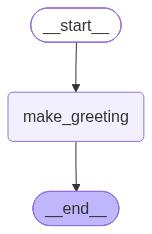

In [3]:
display(graph)

### 🔍 코드 해설

| 줄 | 설명 |
|----|------|
| `class GreetState(TypedDict)` | 그래프가 공유할 데이터의 **모양**. `name`(입력), `greeting`(결과) 두 칸 |
| `return {"greeting": ...}` | **바뀐 칸만** 반환. `name` 은 반환하지 않았지만 **그대로 유지**됨 (결과에 남아 있죠?) |
| `add_edge(START, "make_greeting")` | "시작하면 `make_greeting` 부터" |
| `graph.invoke({"name": "철수"})` | 초기 State 를 넣고 실행. **모든 칸을 채울 필요는 없음** |

### 🖼️ 그래프를 그림으로 보기

`graph.get_graph()` 로 구조를 얻어 **Mermaid 다이어그램**으로 그릴 수 있습니다. 앞으로 모든 장에서 `show_graph(graph)` 로 구조를 확인합니다.
(PNG 렌더링은 인터넷이 필요합니다. 실패하면 Mermaid 텍스트를 출력하니 https://mermaid.live 에 붙여 넣어 보세요.)

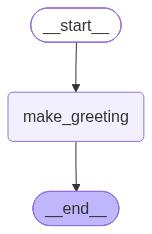

In [4]:
from IPython.display import Image, display

def show_graph(g, xray: bool = False):
    """그래프 구조를 그림으로 보여준다. PNG 실패 시 Mermaid 텍스트를 출력한다."""
    drawable = g.get_graph(xray=xray)
    try:
        display(Image(drawable.draw_mermaid_png()))
    except Exception:
        print(drawable.draw_mermaid())
        print("ℹ️ 위 Mermaid 텍스트를 https://mermaid.live 에 붙여 넣으면 그림으로 볼 수 있어요")

show_graph(graph)

### 🔁 컴파일된 그래프 = `Runnable`

`compile()` 결과는 LangChain 의 `Runnable` 과 같은 인터페이스를 가집니다. 배운 메서드를 그대로 쓸 수 있어요.

| 메서드 | 설명 |
|--------|------|
| `invoke(input)` | 1건 실행 → 최종 State |
| `batch([in1, in2, ...])` | 여러 건을 한 번에 |
| `stream(input)` | 단계별로 결과를 **흘려보내며** 실행 (16장) |
| `ainvoke` / `astream` | 비동기 버전 |

In [5]:
# batch: 여러 입력을 한꺼번에 처리 (결과도 리스트로)
results = graph.batch([{"name": "둘리"}, {"name": "고길동"}])
for r in results:
    print(r)

   ▶ make_greeting 실행! 받은 state = {'name': '둘리'}
   ▶ make_greeting 실행! 받은 state = {'name': '고길동'}
{'name': '둘리', 'greeting': '안녕하세요, 둘리님! 👋'}
{'name': '고길동', 'greeting': '안녕하세요, 고길동님! 👋'}


**📝 정리** — 컴파일된 그래프는 Runnable이라 `batch`로 여러 입력을 한 번에 처리했다.

### ⚠️ 자주 하는 실수
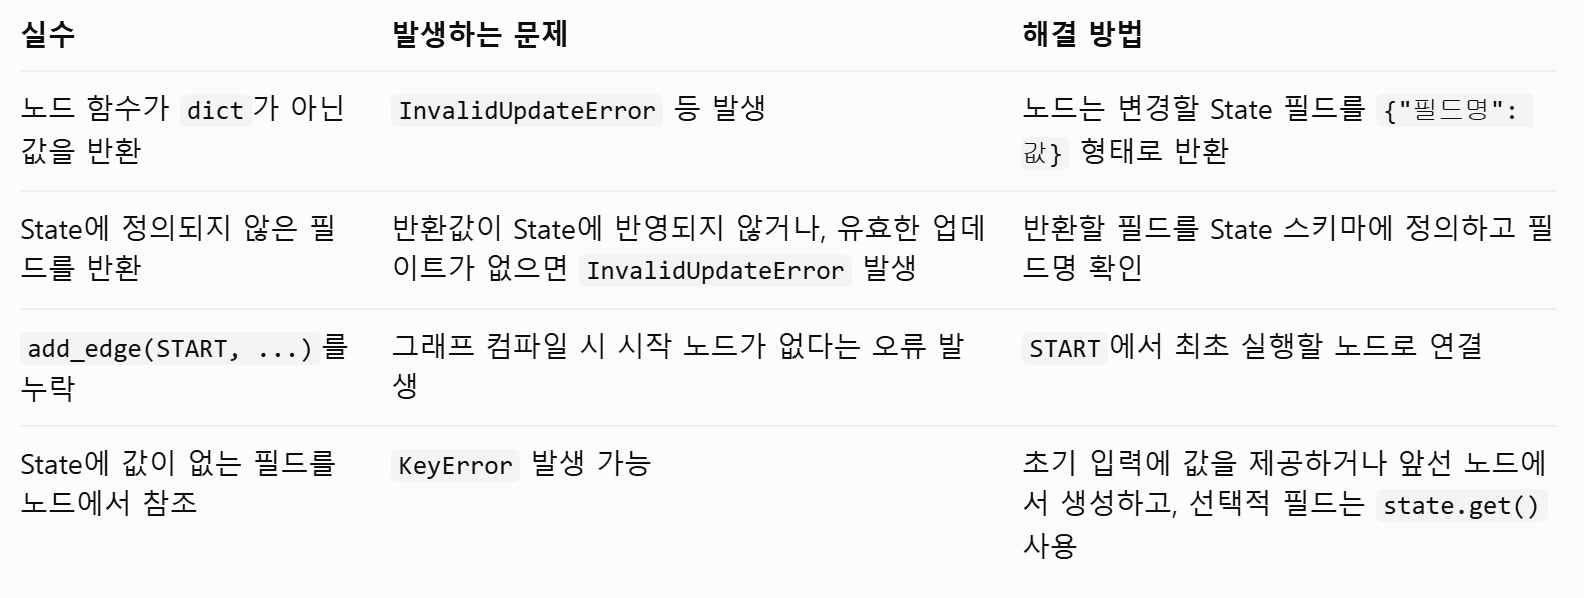

In [6]:
# 🧪 실수 체험: 입력에 없는 필드를 읽으면 어떻게 될까?
class BadState(TypedDict):
    a: int
    b: int

def read_b(state: BadState) -> dict:
    return {"a": state["b"]}          # b 는 입력에 없음!

b = StateGraph(BadState)
b.add_node("read_b", read_b)
b.add_edge(START, "read_b")
b.add_edge("read_b", END)

try:
    b.compile().invoke({"a": 1})      # b 를 주지 않음
except KeyError as e:
    print("❌ KeyError:", e, " ← 아직 채워지지 않은 필드를 읽었기 때문")

❌ KeyError: 'b'  ← 아직 채워지지 않은 필드를 읽었기 때문


**📝 정리** — 입력에 없는 필드 `b`를 읽어서 `KeyError: 'b'`. 앞 노드에서 채우거나 입력으로 주고, 없을 수 있는 값은 `state.get()`으로 읽는다.

- State 정의 (화이트보드 설계)
- Node 함수 작성 (직원이 할 일)
- Builder 로 조립 (직원 배치 + 화살표 연결)
- compile → invoke (실행 가능한 앱으로 변환)

## 🌱 3장. 노드 여러 개 연결하기 — 순차 실행과 상태 갱신 규칙

#### 📖 이론

노드를 `add_edge` 로 이어 붙이면 **앞 노드가 끝난 뒤 뒤 노드가 실행**됩니다.
이때 중요한 규칙은 **"State 가 어떻게 갱신되는가"** 입니다.

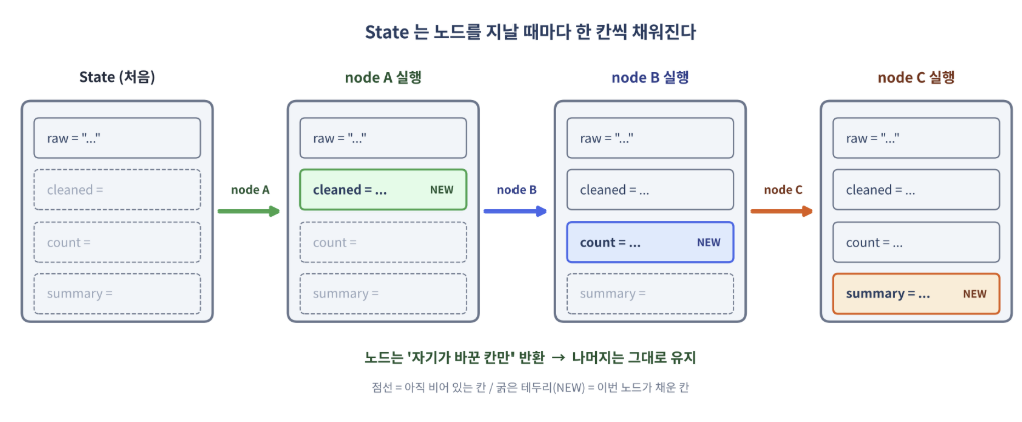

#### 📌 갱신 규칙 (리듀서가 없을 때의 기본 동작)
- 노드가 반환한 필드는 **덮어쓰기**
- 반환하지 않은 필드는 **그대로 유지**

#### 💡 편의 기능: `add_sequence`
일직선 흐름이면 `add_edge` 를 일일이 쓰는 대신 `builder.add_sequence([fn1, fn2, fn3])` 로 한 번에 연결할 수 있습니다. (노드 이름은 **함수 이름**이 됩니다)

In [7]:
class TextState(TypedDict):
    raw: str            # 원본 문장
    cleaned: str        # 정리된 문장
    word_count: int     # 단어 수
    summary: str        # 요약 문구

def clean(state: TextState) -> dict:
    print("   ▶ [1] clean       : 공백 정리 + 소문자 변환")
    return {"cleaned": " ".join(state["raw"].split()).lower()}

def count_words(state: TextState) -> dict:
    print("   ▶ [2] count_words : 단어 수 세기")
    return {"word_count": len(state["cleaned"].split())}

def make_summary(state: TextState) -> dict:
    print("   ▶ [3] make_summary: 요약 문구 만들기")
    return {"summary": f"총 {state['word_count']}단어 → '{state['cleaned']}'"}

builder = StateGraph(TextState)
builder.add_node("clean", clean)
builder.add_node("count_words", count_words)
builder.add_node("make_summary", make_summary)

builder.add_edge(START, "clean")
builder.add_edge("clean", "count_words")
builder.add_edge("count_words", "make_summary")
builder.add_edge("make_summary", END)

text_graph = builder.compile()
result = text_graph.invoke({"raw": "  LangGraph   IS   Fun  "})
print("\n✅ 최종 State:")
for k, v in result.items():
    print(f"   {k:11s}: {v!r}")

   ▶ [1] clean       : 공백 정리 + 소문자 변환
   ▶ [2] count_words : 단어 수 세기
   ▶ [3] make_summary: 요약 문구 만들기

✅ 최종 State:
   raw        : '  LangGraph   IS   Fun  '
   cleaned    : 'langgraph is fun'
   word_count : 3
   summary    : "총 3단어 → 'langgraph is fun'"


### 🔍 코드 해설
- 각 노드는 **자기 일 하나**만 하고 바뀐 칸만 반환합니다. (`clean` 은 `clean`, `count_words` 는 `word_count` …)
- `raw` 는 아무도 안 바꿨으므로 **원본 그대로** 남아 있습니다.
- 이렇게 **"작은 노드 여러 개"** 로 나누면 각 단계를 **따로 테스트·교체·재사용**하기 쉽습니다.

### 👀 각 단계에서 State 가 어떻게 변하는지 보기 — `stream`
- stream_mode="updates": 노드 실행이 완료될 때마다 해당 노드가 State에 반영하도록 반환한 변경 사항을 출력합니다.
- stream_mode="values": 각 슈퍼스텝(Superstep)이 완료될 때마다 변경 사항이 반영된 전체 State를 출력합니다.

> updates는 노드별 변경 내용을, values는 실행 단계별 전체 State를 확인할 때 사용합니다.

In [8]:
print("📦 stream_mode='updates' → 노드별로 '바뀐 부분'만")
for update in text_graph.stream({"raw": "  Hello   World  "}, stream_mode="updates"):
    print("  ", update)

print("\n📦 stream_mode='values' → 매 단계의 '전체 State'")
for snapshot in text_graph.stream({"raw": "  Hello   World  "}, stream_mode="values"):
    print("  ", snapshot)

📦 stream_mode='updates' → 노드별로 '바뀐 부분'만
   ▶ [1] clean       : 공백 정리 + 소문자 변환
   {'clean': {'cleaned': 'hello world'}}
   ▶ [2] count_words : 단어 수 세기
   {'count_words': {'word_count': 2}}
   ▶ [3] make_summary: 요약 문구 만들기
   {'make_summary': {'summary': "총 2단어 → 'hello world'"}}

📦 stream_mode='values' → 매 단계의 '전체 State'
   {'raw': '  Hello   World  '}
   ▶ [1] clean       : 공백 정리 + 소문자 변환
   {'raw': '  Hello   World  ', 'cleaned': 'hello world'}
   ▶ [2] count_words : 단어 수 세기
   {'raw': '  Hello   World  ', 'cleaned': 'hello world', 'word_count': 2}
   ▶ [3] make_summary: 요약 문구 만들기
   {'raw': '  Hello   World  ', 'cleaned': 'hello world', 'word_count': 2, 'summary': "총 2단어 → 'hello world'"}


**📝 정리** — `updates`는 노드별로 바뀐 부분만(`{'clean': {'cleaned': 'hello world'}}`), `values`는 슈퍼스텝마다 전체 State를 보여 준다. 어느 노드가 무엇을 바꿨는지 추적할 때 쓴다.

### ✂️ `add_sequence` 로 줄이기

같은 그래프를 **훨씬 짧게** 만들 수 있습니다. (노드 이름 = 함수 이름: `clean`, `count_words`, `make_summary`)

   ▶ [1] clean       : 공백 정리 + 소문자 변환
   ▶ [2] count_words : 단어 수 세기
   ▶ [3] make_summary: 요약 문구 만들기
총 2단어 → 'short cut'


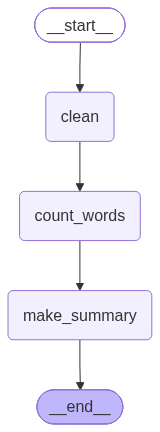

In [9]:
builder = StateGraph(TextState)
builder.add_sequence([clean, count_words, make_summary])   # 노드 등록 + 순서대로 연결을 한 번에
builder.add_edge(START, "clean")                           # 시작점과 끝점은 직접 연결
builder.add_edge("make_summary", END)

seq_graph = builder.compile()
print(seq_graph.invoke({"raw": "  Short   Cut  "})["summary"])
show_graph(seq_graph)

**📝 정리** — `add_sequence`로 노드 등록 + 순서 연결을 한 번에 했다(노드 이름 = 함수 이름). START와 END 연결은 직접 해야 한다.

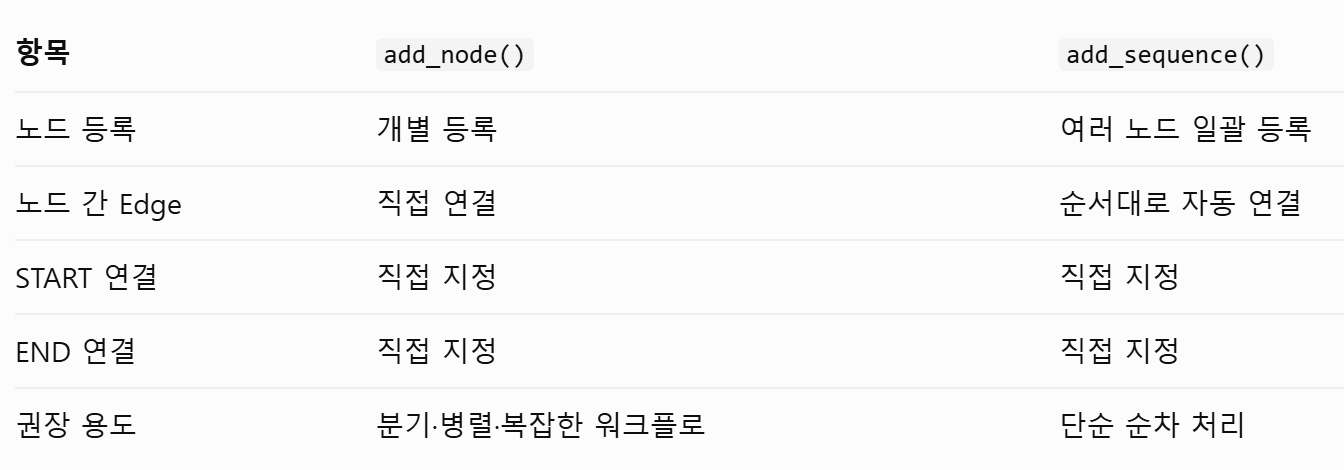

### ⚠️ 자주 하는 실수
- **노드가 모든 필드를 다시 반환할 필요는 없습니다.** 바뀐 것만 반환하세요. (전부 반환해도 동작은 하지만 "누가 뭘 바꿨는지" 가 흐려집니다)
- 노드 이름(`"clean"`)과 State 필드 이름이 겹치면 읽기 혼란스러우니, **노드는 동사(`clean`), 필드는 명사(`cleaned`)** 로 이름 짓는 습관을 추천합니다.

## 🌱 4장. State 스키마 — `TypedDict` · `dataclass` · `Pydantic`

### 📖 이론

State 의 모양을 정의하는 방법은 3가지입니다. **하는 일은 같고**, 편의성과 검증 수준이 다릅니다.

| 방식 | 노드에서 읽기 | 기본값 | 입력 검증 | 특징 |
|------|---------------|:------:|:---------:|------|
| **`TypedDict`** | `state["name"]` | ❌ | ❌ | 가장 가볍고 **가장 많이 씀** |
| **`dataclass`** | `state.name` | ✅ | ❌ | 속성 접근 + 기본값 |
| **`Pydantic BaseModel`** | `state.name` | ✅ | ✅ | **타입 검증** 까지 (입력이 틀리면 에러) |

<br>

> 📌 어떤 방식을 쓰든 노드의 **반환값은 `dict`**, `invoke` 의 **결과도 `dict`** 입니다.



#### 🎯 LangGraph의 State 스키마: Input · Overall · Output

- **builder = StateGraph(OverallState)**
- builder = StateGraph(OverallState, input_schema=InputState, output_schema=OutputState)

InputState는 외부에서 입력받을 데이터, OverallState는 그래프 내부 노드들이 공유할 데이터, OutputState는 그래프 실행 결과로 외부에 반환할 데이터를 정의하는 스키마입니다.

In [10]:
from dataclasses import dataclass
from pydantic import BaseModel, ValidationError

# ───── (a) TypedDict : state["필드"] ─────
class TDState(TypedDict):
    count: int

def td_node(state: TDState) -> dict:
    return {"count": state["count"] + 1}

# ───── (b) dataclass : state.필드  (+ 기본값) ─────
@dataclass
class DCState:
    count: int = 100

def dc_node(state: DCState) -> dict:
    return {"count": state.count + 1}

# ───── (c) Pydantic : state.필드  (+ 타입 검증) ─────
class PDState(BaseModel):
    count: int = 10

def pd_node(state: PDState) -> dict:
    return {"count": state.count + 1}

def build(schema, node):
    b = StateGraph(schema)
    b.add_node("inc", node)
    
    b.add_edge(START, "inc")
    b.add_edge("inc", END)
    return b.compile()

In [11]:

print("TypedDict :", build(TDState, td_node).invoke({"count": 1}))
print("dataclass :", build(DCState, dc_node).invoke({"count": 1}))
print("dataclass (기본값 사용):", build(DCState, dc_node).invoke({}))
print("Pydantic  :", build(PDState, pd_node).invoke({"count": 1}))

# Pydantic 의 장점: 잘못된 타입의 입력을 막아 줌
try:
    build(PDState, pd_node).invoke({"count": "abc"})
except ValidationError as e:
    print("\n❌ Pydantic 검증 실패 → 잘못된 입력을 차단:", e.errors()[0]["msg"])

TypedDict : {'count': 2}
dataclass : {'count': 2}
dataclass (기본값 사용): {'count': 101}
Pydantic  : {'count': 2}

❌ Pydantic 검증 실패 → 잘못된 입력을 차단: Input should be a valid integer, unable to parse string as an integer


**📝 정리** — dataclass는 `{}`만 넣어도 기본값 100 → 101, Pydantic은 `"abc"`를 넣으면 `ValidationError`로 막았다. 결과는 세 방식 모두 dict.

### 🎯 입력/출력 스키마 분리 실습

"질문(`question`)만 받고 **답변(`answer`)만** 돌려주는" 그래프. 중간에 쓰는 `scratch`(메모) 필드는 **밖으로 새어 나가지 않게** 숨깁니다.

In [12]:
class InputSchema(TypedDict):
    question: str

class OutputSchema(TypedDict):
    answer: str

class FullState(InputSchema, OutputSchema):      # 전체 State = 입력 + 출력 + 내부 필드
    scratch: str                                               # 내부 작업용 (밖으로 노출 ❌)

def think(state: FullState) -> dict:
    return {"scratch": f"'{state['question']}' 에 대해 생각 중…"}

def reply(state: FullState) -> dict:
    return {"answer": f"{state['scratch']} → 결론: 좋은 질문이에요!"}


In [13]:
# ① 스키마를 분리하지 않은 경우
b = StateGraph(FullState)
b.add_node("think", think); b.add_node("reply", reply)
b.add_edge(START, "think"); b.add_edge("think", "reply"); b.add_edge("reply", END)
print("① 분리 안 함 →", b.compile().invoke({"question": "LangGraph?"}))

① 분리 안 함 → {'question': 'LangGraph?', 'answer': "'LangGraph?' 에 대해 생각 중… → 결론: 좋은 질문이에요!", 'scratch': "'LangGraph?' 에 대해 생각 중…"}


In [14]:
# ② 입력/출력 스키마를 분리한 경우
b = StateGraph(FullState, input_schema=InputSchema, output_schema=OutputSchema)
b.add_node("think", think); b.add_node("reply", reply)
b.add_edge(START, "think"); b.add_edge("think", "reply"); b.add_edge("reply", END)
print("② 분리함     →", b.compile().invoke({"question": "LangGraph?"}))

② 분리함     → {'answer': "'LangGraph?' 에 대해 생각 중… → 결론: 좋은 질문이에요!"}


**📝 정리** — `output_schema`를 지정하자 내부 필드 `scratch` 없이 `answer`만 반환됐다.

### 🔍 정리
- ①은 내부 필드(`scratch`)까지 **모두 반환**, ②는 `OutputSchema` 에 정의한 **`answer` 만** 반환합니다.
- 일반적인 학습/프로토타입은 **`TypedDict`** 로 충분합니다. **입력 검증이 중요**하면 Pydantic, **기본값이 편하면** dataclass 를 쓰세요.

![LangGraph 기본 사용법 인포그래픽 정리.png](<attachment:LangGraph 기본 사용법 인포그래픽 정리.png>)
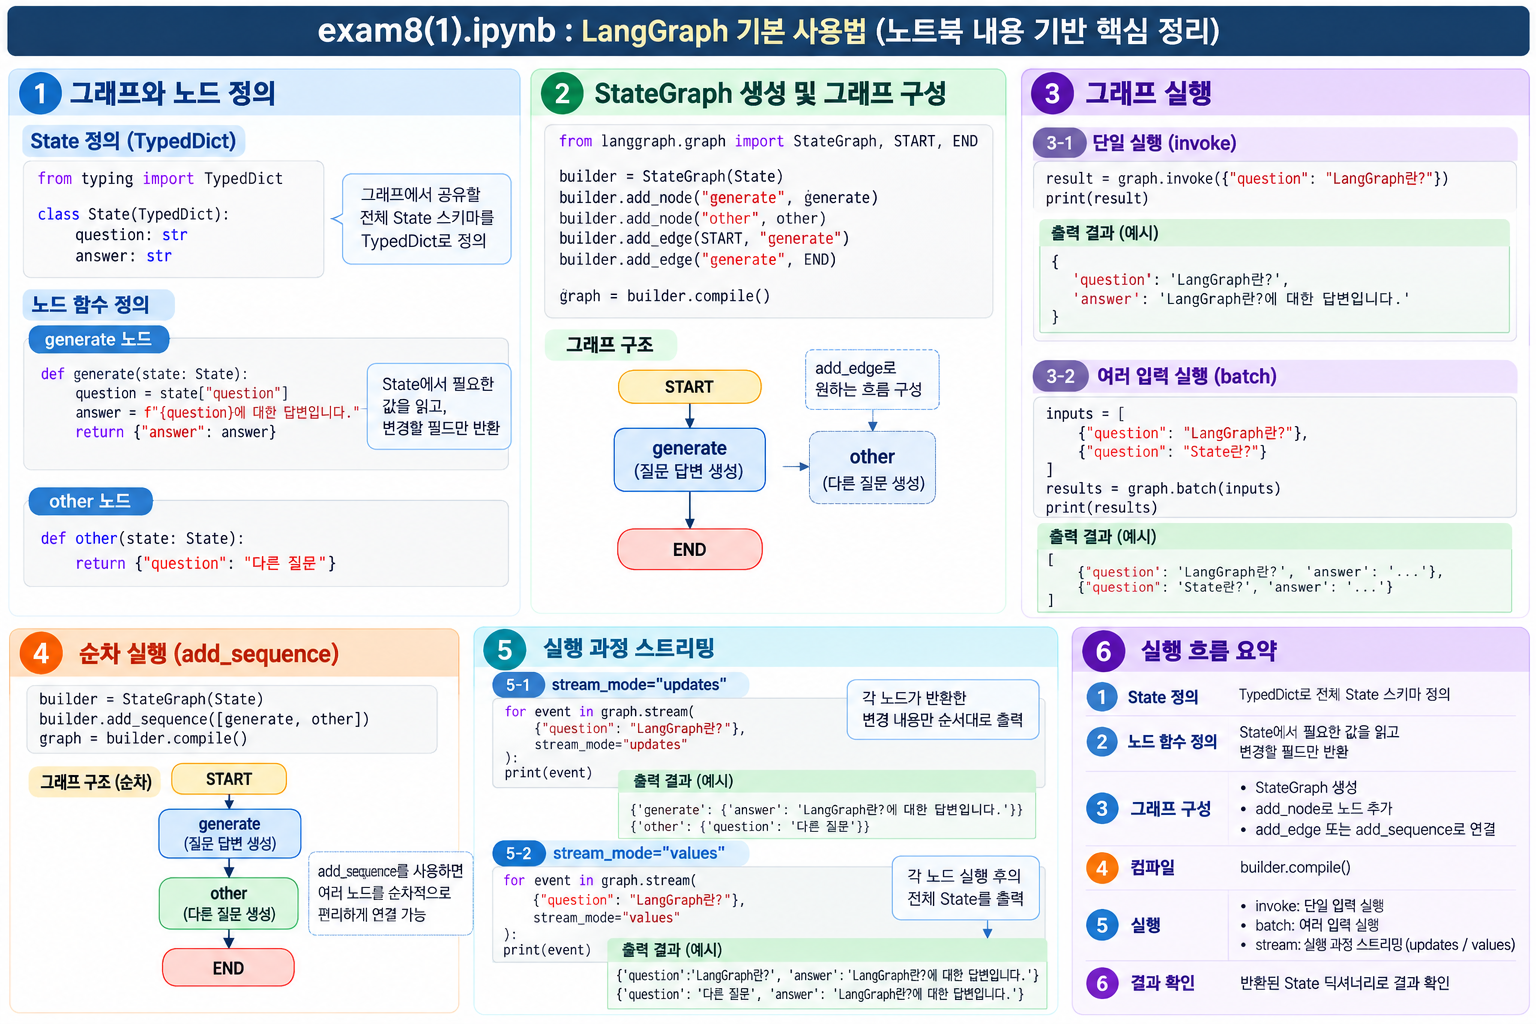

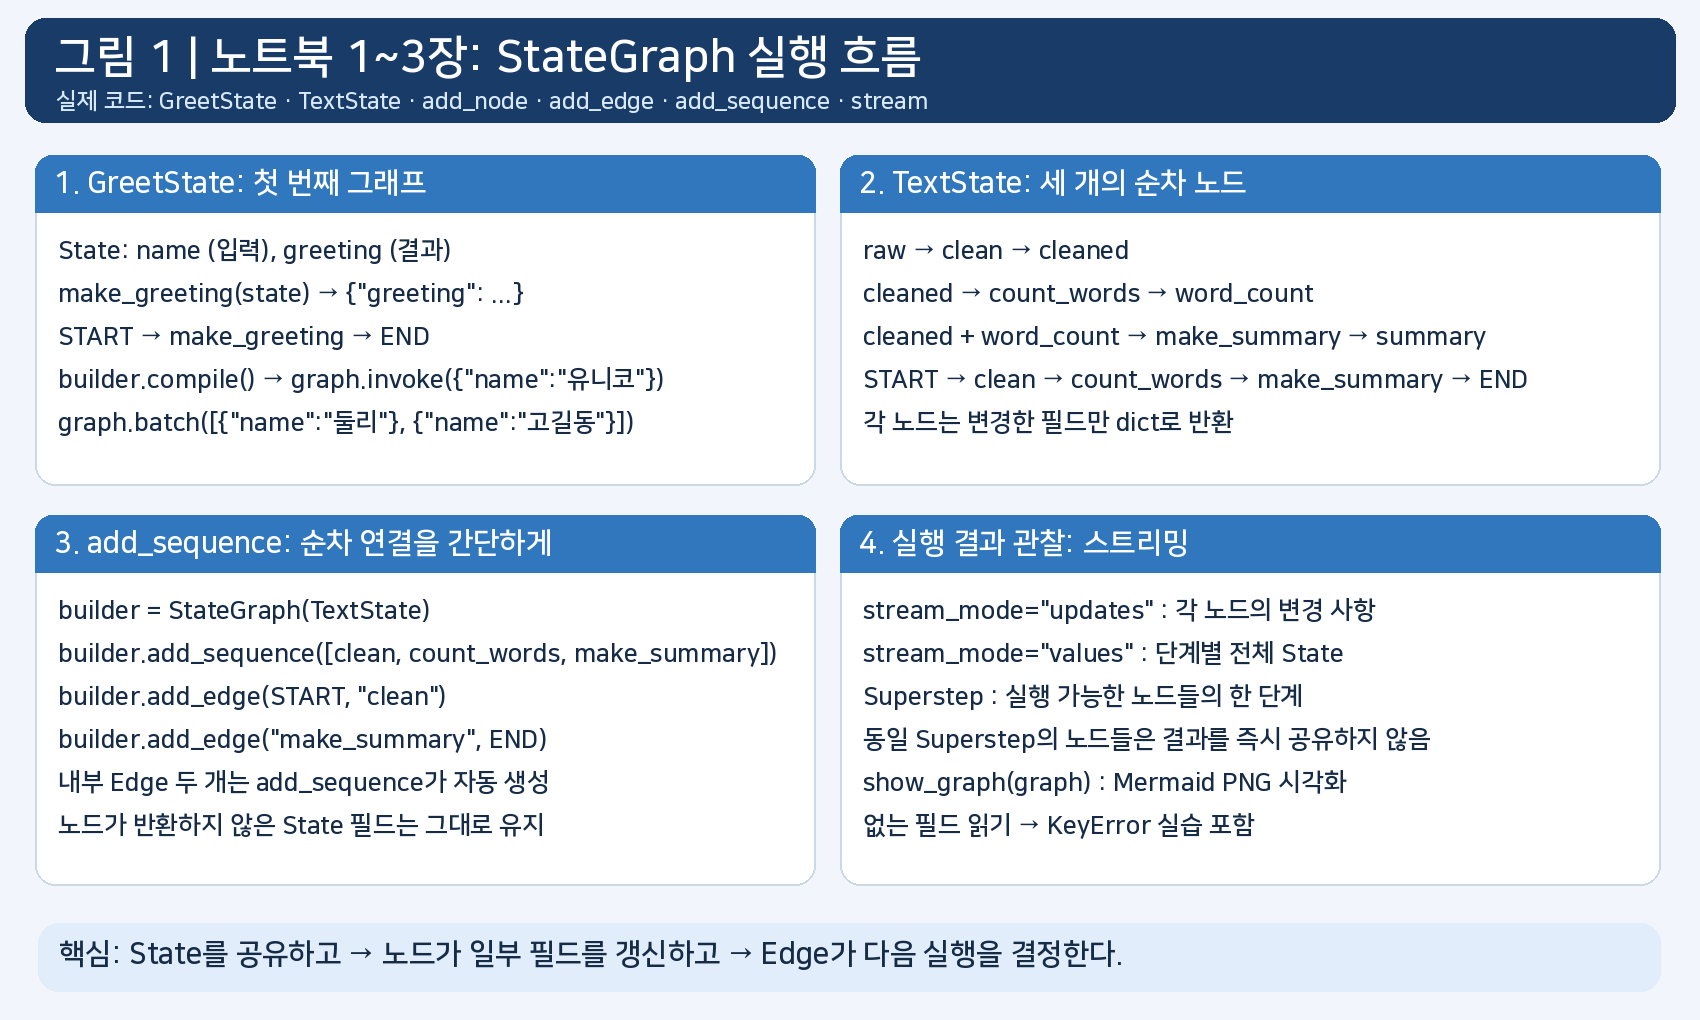

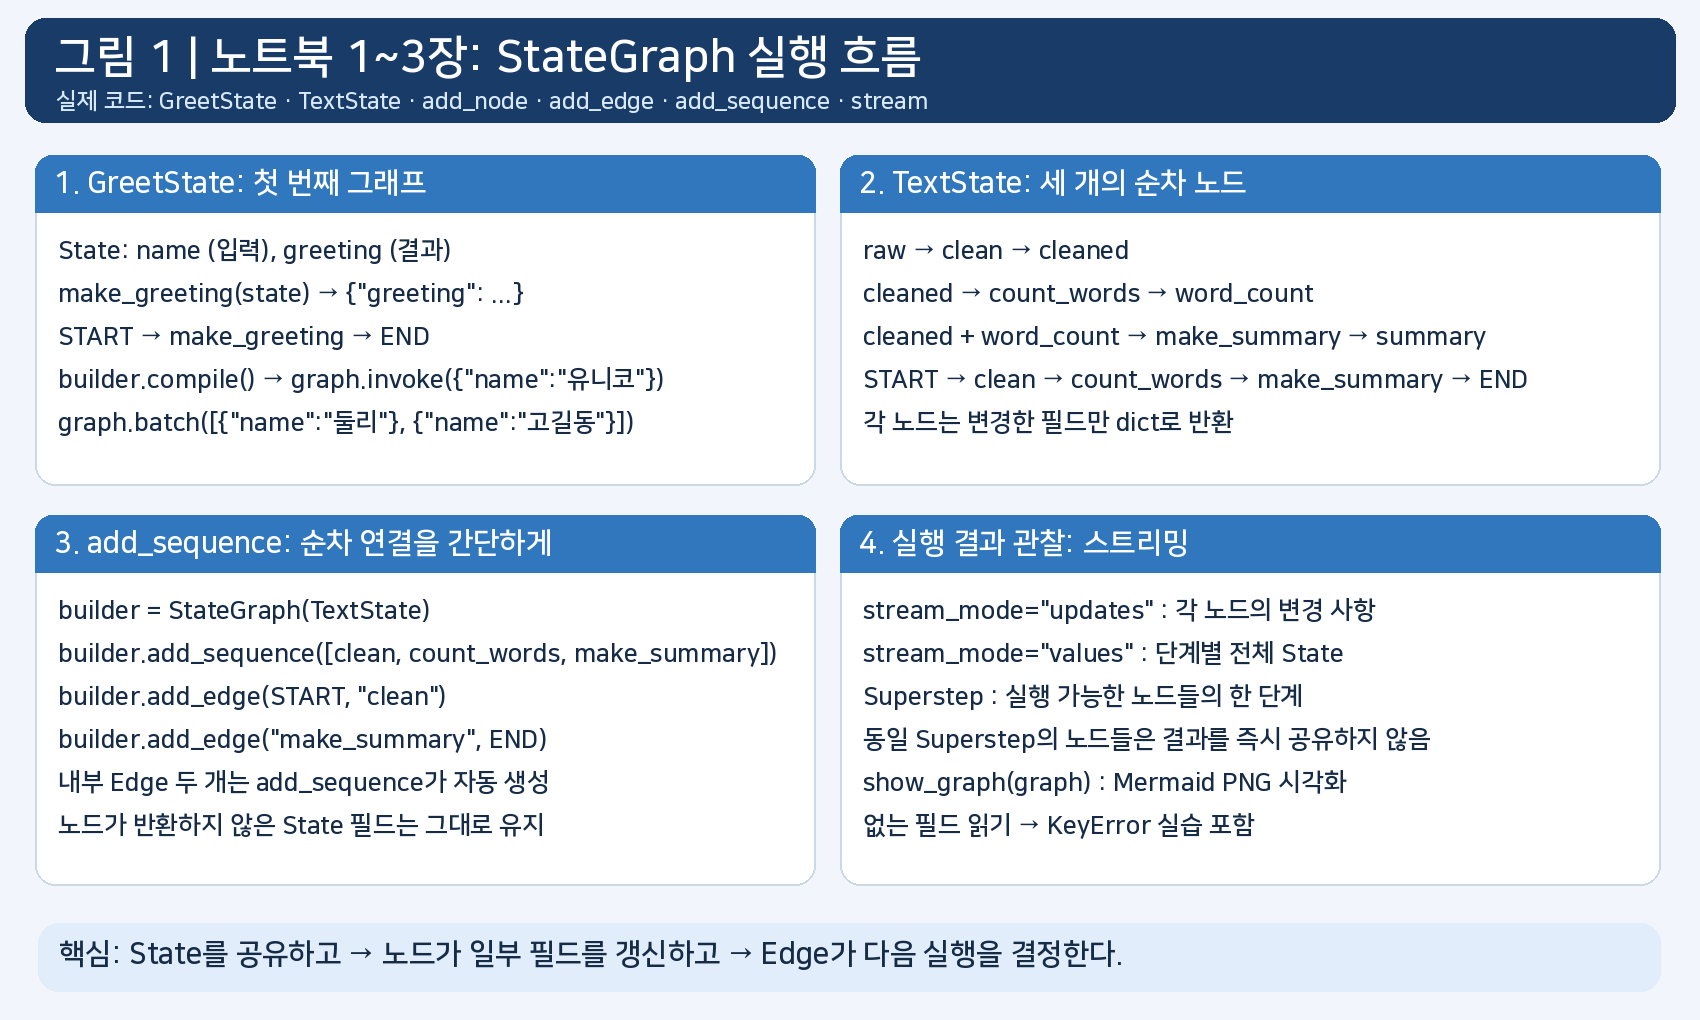

## 🔁 복습 질문

<details>
<summary>1. 노드 함수가 반환해야 하는 것은?</summary>

바뀐 필드만 담은 dict. 반환하지 않은 필드는 그대로 유지된다.
</details>

<details>
<summary>2. <code>compile()</code>이 하는 일은?</summary>

설계도(builder)를 실행 가능한 그래프(Runnable)로 바꾸고, 시작 노드가 없는 등 연결 오류를 검사한다.
</details>

<details>
<summary>3. <code>stream_mode="updates"</code>와 <code>"values"</code>의 차이는?</summary>

노드별 변경분 / 슈퍼스텝별 전체 State.
</details>

<details>
<summary>4. State 스키마 세 가지 방식 중 입력 타입을 검증해 주는 것은?</summary>

Pydantic BaseModel.
</details>
